<a href="https://colab.research.google.com/github/antonioboboc/covd19-ct-scan-segmentation/blob/main/notebooks/03_antrenare_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

intrare = layers.Input(shape=(256, 256, 1))

caracteristici = layers.Conv2D(
    filters=16,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="conv_encoder_1",
)(intrare)

rezolutie_redusa = layers.MaxPooling2D(
    pool_size=2,
    name="pool_encoder_1",
)(caracteristici)

print("Intrare CT:", intrare.shape)
print("După convoluție:", caracteristici.shape)
print("După pooling:", rezolutie_redusa.shape)

Intrare CT: (None, 256, 256, 1)
După convoluție: (None, 256, 256, 16)
După pooling: (None, 128, 128, 16)


In [2]:
encoder_2 = layers.Conv2D(
    32, 3, padding="same", activation="relu", name="conv_encoder_2"
)(rezolutie_redusa)
pool_2 = layers.MaxPooling2D(pool_size=2, name="pool_encoder_2")(encoder_2)

encoder_3 = layers.Conv2D(
    64, 3, padding="same", activation="relu", name="conv_encoder_3"
)(pool_2)
pool_3 = layers.MaxPooling2D(pool_size=2, name="pool_encoder_3")(encoder_3)

centru = layers.Conv2D(
    128, 3, padding="same", activation="relu", name="conv_centru"
)(pool_3)

print("După al doilea bloc:", pool_2.shape)
print("După al treilea bloc:", pool_3.shape)
print("Intrarea în decoder:", centru.shape)


După al doilea bloc: (None, 64, 64, 32)
După al treilea bloc: (None, 32, 32, 64)
Intrarea în decoder: (None, 32, 32, 128)


In [3]:
def bloc_decoder(tensor, filtre, nivel):
    tensor = layers.UpSampling2D(
        size=2, name=f"upsampling_{nivel}"
    )(tensor)
    return layers.Conv2D(
        filtre, 3, padding="same", activation="relu",
        name=f"conv_decoder_{nivel}",
    )(tensor)


decoder_1 = bloc_decoder(centru, 64, 1)
decoder_2 = bloc_decoder(decoder_1, 32, 2)
decoder_3 = bloc_decoder(decoder_2, 16, 3)

iesire = layers.Conv2D(
    1, 1, activation="sigmoid", name="probabilitate_leziune"
)(decoder_3)

model_cnn = tf.keras.Model(intrare, iesire, name="cnn_propriu")

print("După primul bloc din decoder:", decoder_1.shape)
print("După al doilea bloc:", decoder_2.shape)
print("După al treilea bloc:", decoder_3.shape)
print("Iesire CNN:", model_cnn.output_shape)
print("Numar de parametri:", model_cnn.count_params())

După primul bloc din decoder: (None, 64, 64, 64)
După al doilea bloc: (None, 128, 128, 32)
După al treilea bloc: (None, 256, 256, 16)
Ieșire CNN: (None, 256, 256, 1)
Număr de parametri: 194049


In [4]:
def cost_bce_dice(masca_reala, masca_prezisa):
    masca_reala = tf.cast(masca_reala, tf.float32)
    masca_prezisa = tf.cast(masca_prezisa, tf.float32)

    bce_pixeli = tf.keras.losses.binary_crossentropy(
        masca_reala, masca_prezisa
    )
    bce_pe_imagine = tf.reduce_mean(bce_pixeli, axis=(1, 2))

    axe = (1, 2, 3)
    suprapunere = tf.reduce_sum(masca_reala * masca_prezisa, axis=axe)
    total = (
        tf.reduce_sum(masca_reala, axis=axe)
        + tf.reduce_sum(masca_prezisa, axis=axe)
    )
    dice = (2.0 * suprapunere + 1.0) / (total + 1.0)

    return bce_pe_imagine + (1.0 - dice)


model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=cost_bce_dice,
)

print("Funcție de cost: BCE + Dice loss")
print("Optimizator: Adam, rată de învățare 0.001")

Funcție de cost: BCE + Dice loss
Optimizator: Adam, rată de învățare 0.001


In [5]:
import subprocess
import sys
from pathlib import Path

repo = Path("/content/covd19-ct-scan-segmentation")

if not repo.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/antonioboboc/covd19-ct-scan-segmentation.git", str(repo)],
        check=True,
    )

sys.path.insert(0, str(repo / "src"))
from date_ct import pregateste_seturi

seturi = pregateste_seturi(
    cale_csv=repo / "splits" / "partitii_ct.csv",
    folder_date="/content/ct_lesiuni",
    marime_lot=8,
)

set_antrenare = seturi["Antrenare"]
set_validare = seturi["Validare"]
set_test = seturi["Test"]

imagini_lot, masti_lot = next(iter(set_antrenare))
print("Imagini:", imagini_lot.shape)
print("Măști:", masti_lot.shape)
print("Loturi de antrenare:", len(set_antrenare))
print("Loturi de validare:", len(set_validare))

Descarc arhiva Kaggle...
Extrag imaginile si mastile...
Imagini: (8, 256, 256, 1)
Măști: (8, 256, 256, 1)
Loturi de antrenare: 230
Loturi de validare: 38


In [8]:
from time import perf_counter

cale_ponderi = "/content/cnn_propriu.weights.h5"

salveaza_ponderi = tf.keras.callbacks.ModelCheckpoint(
    filepath=cale_ponderi,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
)

oprire_timpurie = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=4,
    restore_best_weights=True,
)

inceput = perf_counter()

istoric_cnn = model_cnn.fit(
    set_antrenare,
    validation_data=set_validare,
    epochs=20,
    callbacks=[salveaza_ponderi, oprire_timpurie],
)

timp_cnn = perf_counter() - inceput
print(f"Timp de antrenare CNN: {timp_cnn / 60:.2f} minute")
print(f"Cea mai mica pierdere pe validare: {min(istoric_cnn.history['val_loss']):.4f}")
print(f"Ponderi salvate in {cale_ponderi}")

Epoch 1/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 37s 161ms/step - loss: 0.3490 - val_loss: 0.4435
Epoch 2/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 137ms/step - loss: 0.3423 - val_loss: 0.4643
Epoch 3/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - loss: 0.3405 - val_loss: 0.4404
Epoch 4/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 135ms/step - loss: 0.3342 - val_loss: 0.4502
Epoch 5/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - loss: 0.3378 - val_loss: 0.4345
Epoch 6/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 133ms/step - loss: 0.3280 - val_loss: 0.4492
Epoch 7/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 35s 153ms/step - loss: 0.3216 - val_loss: 0.4329
Epoch 8/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 133ms/step - loss: 0.3176 - val_loss: 0.4463
Epoch 9/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 32s 138ms/step - loss: 0.3111 - val_loss: 0.4458
Epoch 10/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - loss: 0.3106 - val_loss: 0.4514
Epoch 11/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 31s 135ms/step - loss: 0.3211 - val_loss: 0.4425
Timp de antrenare C

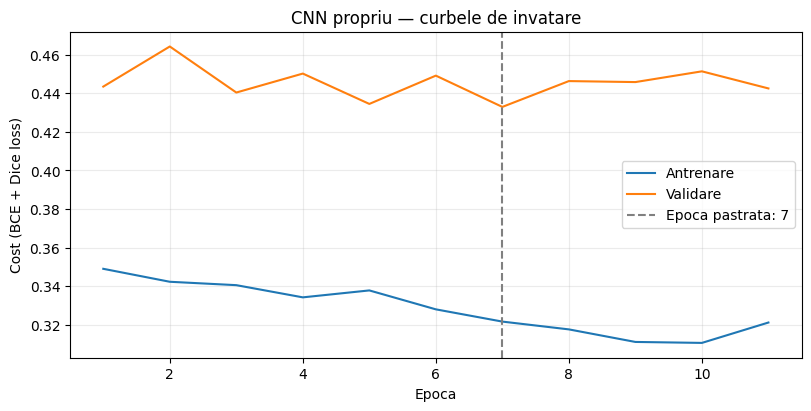

In [10]:
import matplotlib.pyplot as plt

pierdere_antrenare = istoric_cnn.history["loss"]
pierdere_validare = istoric_cnn.history["val_loss"]
epoci = range(1, len(pierdere_validare) + 1)
epoca_optima = min(epoci, key=lambda epoca: pierdere_validare[epoca - 1])

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(epoci, pierdere_antrenare, label="Antrenare")
ax.plot(epoci, pierdere_validare, label="Validare")
ax.axvline(
    epoca_optima,
    color="gray",
    linestyle="--",
    label=f"Epoca pastrata: {epoca_optima}",
)

ax.set(
    title="CNN propriu — curbele de invatare",
    xlabel="Epoca",
    ylabel="Cost (BCE + Dice loss)",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

In [11]:
from google.colab import files

files.download("/content/cnn_propriu.weights.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>